# HS4002 Week 9

## Principal components analysis

A principal component is a linear combination of the variables. PCA reduces them to a smaller number of uncorrelated components.

The worked example uses five GSS variables: income, occupational prestige, education, number of children, and age. Each is scaled to mean 0 and SD 1. We fit the model with `sklearn.decomposition.PCA` and draw the scree plot with `plotnine`.


In [1]:
# !pip install pandas numpy plotnine scikit-learn statsmodels

import pandas as pd
import numpy as np
from plotnine import *
import warnings
warnings.filterwarnings('ignore')


In [2]:
raw_df = pd.read_csv("gss2022_mini2.csv")

chosen_variables = [
	'id', 'age', 'happy', 'yrlvmus', 'yrartxbt', 'yrmovie', 'yrcreat',
	'income16', 'prestg10', 'degree', 'biokids', 'educ'
]
df = raw_df[chosen_variables].copy()

income_map = {
	1: 500,    2: 2000,   3: 3500,   4: 4500,   5: 5500,   6: 6500,
	7: 7500,   8: 9000,   9: 11250,  10: 13750, 11: 16250, 12: 18750,
	13: 21250, 14: 23750, 15: 27500, 16: 32500, 17: 37500, 18: 45000,
	19: 55000, 20: 67500, 21: 82500, 22: 100000, 23: 120000, 24: 140000,
	25: 160000, 26: 250000
}
df['income_cont'] = df['income16'].map(income_map)

df['binary_lvmus']  = (df['yrlvmus']  == 1).astype(int)
df['binary_artxbt'] = (df['yrartxbt'] == 1).astype(int)
df['binary_movie']  = (df['yrmovie']  == 1).astype(int)
df['binary_creat']  = (df['yrcreat']  == 1).astype(int)
df['ba_binary']     = (df['degree'] >= 3).astype(int)
df['happy_bin']     = (df['happy'] <= 2).astype(int)


# Steps

1. Choose the variables.
2. Scale each one to mean 0 and SD 1.
3. Fit the PCA.
4. Decide how many components to keep. The scree plot is the guide. There is no single rule.
5. Read the loadings.
6. Use the components in a plot or a regression.


## 1. Choose the variables

`income_cont` is income in dollars. `prestg10` is occupational prestige. `educ` is years of schooling. `biokids` is the number of children. `age` is age in years.


In [3]:
cols = ["income_cont", "prestg10", "educ", "biokids", "age"]
work = df.dropna(subset=cols).copy()
work[cols].describe().round(1)


,income_cont,prestg10,educ,biokids,age
count,1056.0,1056.0,1056.0,1056.0,1056.0
mean,86222.1,46.8,14.9,1.6,50.9
std,72378.7,13.3,2.7,1.5,17.3
min,500.0,17.0,2.0,0.0,18.0
25%,32500.0,36.0,13.0,0.0,36.0
50%,67500.0,47.0,15.0,2.0,51.0
75%,120000.0,59.0,16.0,2.0,66.0
max,250000.0,80.0,20.0,11.0,89.0


## 2--3. Scale, then fit

`StandardScaler` subtracts the mean and divides by the standard deviation. Without that step, income, which is measured in dollars, would dominate the first component.


In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(work[cols])
pca = PCA().fit(X)

prop = pca.explained_variance_ratio_
print(pd.DataFrame({
    "Standard deviation": pca.explained_variance_ ** 0.5,
    "Proportion of variance": prop,
    "Cumulative proportion": prop.cumsum(),
}, index=["PC1", "PC2", "PC3", "PC4", "PC5"]).T.round(3))


                          PC1    PC2    PC3    PC4    PC5
Standard deviation      1.368  1.127  0.882  0.781  0.689
Proportion of variance  0.374  0.254  0.155  0.122  0.095
Cumulative proportion   0.374  0.628  0.783  0.905  1.000


PC1 accounts for 37.4 per cent of the variance. The first two components together account for 62.8 per cent.


## 4. Loadings

In `sklearn`, each row of `pca.components_` is one component. Transposing it puts the variables in the rows, so each column is a component. A large loading means that variable defines that component.


In [5]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=cols,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"],
)
print(loadings.round(3))


               PC1    PC2    PC3    PC4    PC5
income_cont  0.524  0.009 -0.517  0.676 -0.030
prestg10     0.592  0.095  0.042 -0.457 -0.656
educ         0.594 -0.112  0.209 -0.268  0.721
biokids     -0.098  0.710 -0.560 -0.351  0.223
age          0.109  0.689  0.612  0.373 -0.022


How would you describe PC1 and PC2?

PC1 loads on income, occupational prestige, and education. PC2 loads on number of children and age.


## 5. How many components?

Look for an elbow in the scree plot: the point where adding another component buys little extra variance.


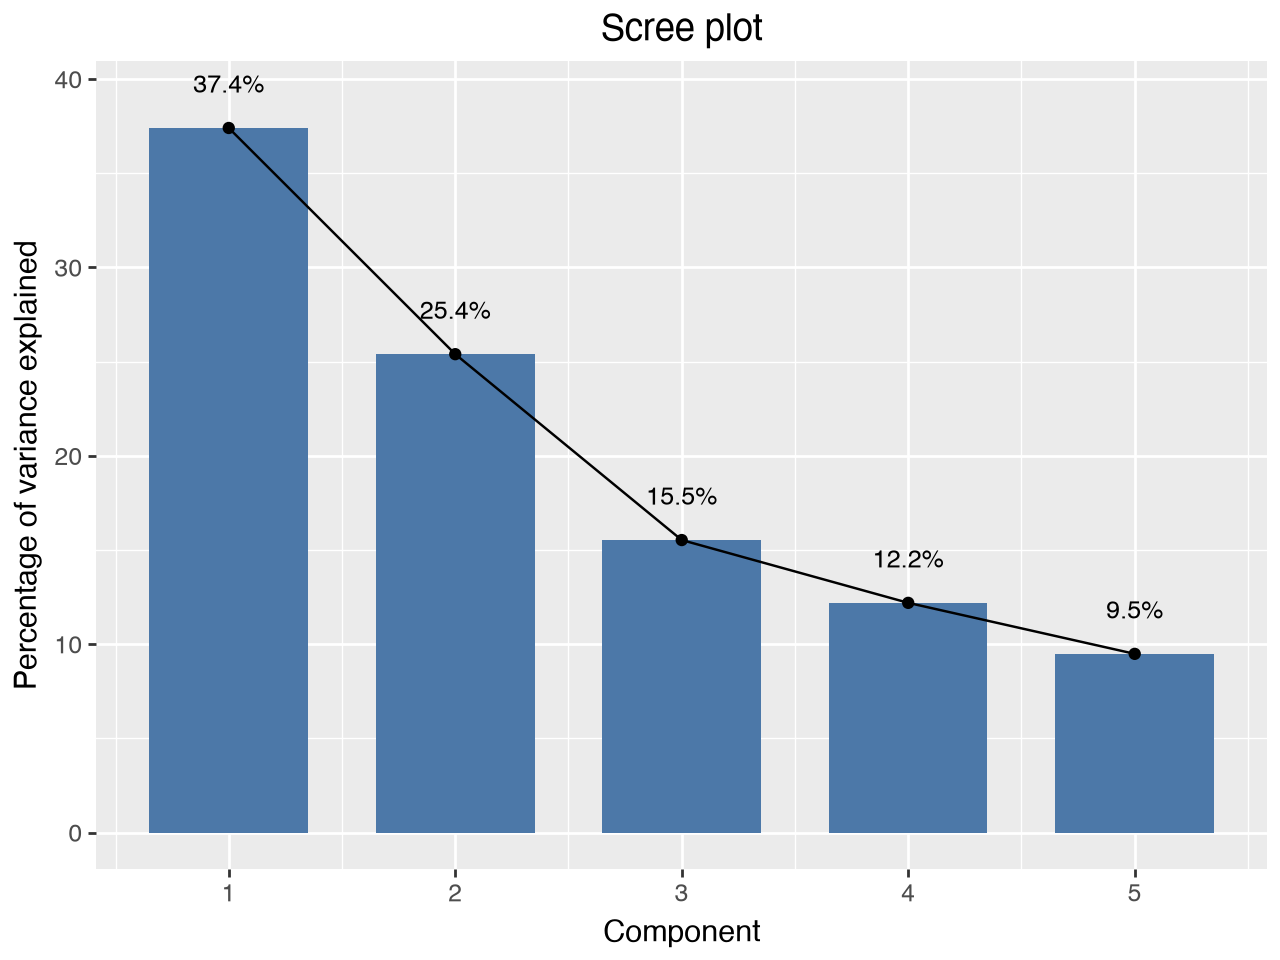

In [6]:
scree = pd.DataFrame({
    "component": range(1, 6),
    "percent": pca.explained_variance_ratio_ * 100,
})
scree["label"] = scree["percent"].map(lambda p: f"{p:.1f}%")

(
    ggplot(scree, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.6, size=9, va="bottom")
    + labs(x="Component", y="Percentage of variance explained", title="Scree plot")
)


## 6. Use the components

The first two components locate each person in a plane. Colour the points by whether the person has a BA. A BA was not one of the five variables in the PCA, so the colour is a separate fact about the person.


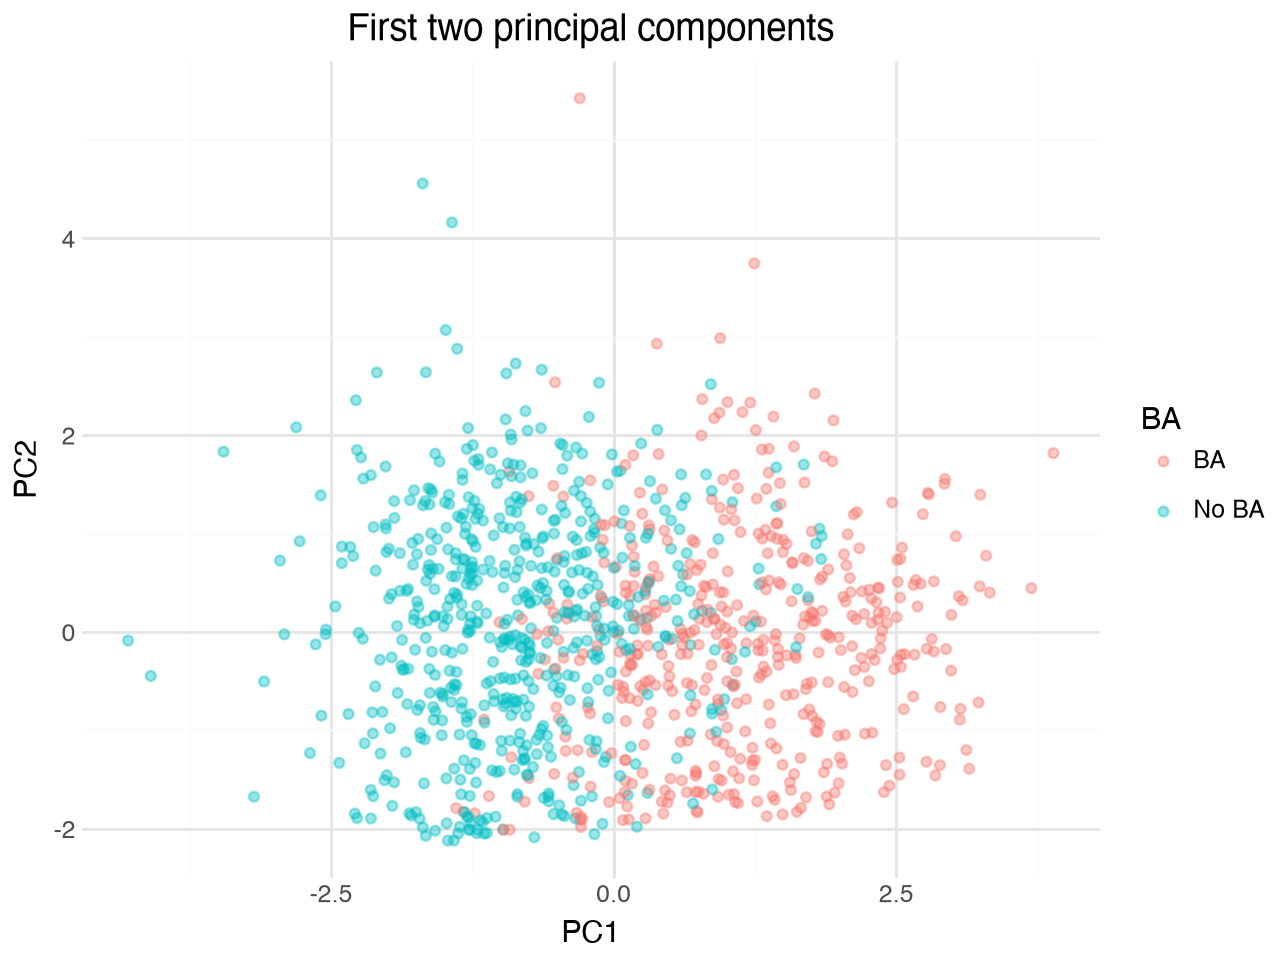

In [7]:
scores = pca.transform(X)
plot_df = work.copy()
plot_df["PC1"] = scores[:, 0]
plot_df["PC2"] = scores[:, 1]
plot_df["BA"] = np.where(plot_df["ba_binary"] == 1, "BA", "No BA")

(
    ggplot(plot_df, aes("PC1", "PC2", color="BA"))
    + geom_point(alpha=0.4, size=1.5)
    + theme_minimal()
    + labs(x="PC1", y="PC2", title="First two principal components")
)


## 7. A linear model for PC1

PC1 is the dependent variable. `ba_binary` is the independent variable: 1 is a BA, 0 is not.

This is an OLS model. The coefficient on `ba_binary` is the expected difference in PC1 between a person with a BA and a person without one.


In [8]:
import statsmodels.formula.api as smf

lm_pc1 = smf.ols("PC1 ~ ba_binary", data=plot_df).fit()
print(lm_pc1.summary())

                            OLS Regression Results                            
Dep. Variable:                    PC1   R-squared:                       0.508
Model:                            OLS   Adj. R-squared:                  0.508
Method:                 Least Squares   F-statistic:                     1090.
Date:                Mon, 19 Oct 2026   Prob (F-statistic):          9.80e-165
Time:                        13:48:05   Log-Likelihood:                -1453.9
No. Observations:                1056   AIC:                             2912.
Df Residuals:                    1054   BIC:                             2922.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.8650      0.039    -21.911      0.0

The coefficient on ba_binary shows the average difference in PC1 scores between respondents with and without a BA. A positive coefficient means respondents with a BA have higher PC1 scores on average, and conversely, a negative coefficient means they have lower PC1 scores.

## 8. A logit model for a BA

`ba_binary` is now the dependent variable, and PC1 and PC2 are the independent variables. `ba_binary` is coded 0 or 1, so we fit a logit.

The coefficient is the expected change in the log odds of having a BA. Exponentiating it gives the factor by which the odds change.


In [9]:
logit_ba = smf.logit("ba_binary ~ PC1 + PC2", data=plot_df).fit()
print(logit_ba.summary())

Optimization terminated successfully.
         Current function value: 0.340435
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              ba_binary   No. Observations:                 1056
Model:                          Logit   Df Residuals:                     1053
Method:                           MLE   Df Model:                            2
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.5037
Time:                        13:48:25   Log-Likelihood:                -359.50
converged:                       True   LL-Null:                       -724.43
Covariance Type:            nonrobust   LLR p-value:                3.259e-159
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3769      0.095     -3.972      0.000      -0.563      -0.191
PC1            2.0936      0.

In [10]:
print(np.exp(logit_ba.params))

Intercept    0.686001
PC1          8.113871
PC2          0.675958
dtype: float64


A positive coefficient means that higher scores on that principal component are associated with higher odds of having a BA. Exponentiating the coefficient gives the factor by which the odds change for a one-unit increase in the component.

# Independent exercise

Use `happy_bin` as the dependent variable. Build the components from `income_cont`, `prestg10`, `educ`, `age`, and the four cultural-participation indicators (`binary_lvmus`, `binary_artxbt`, `binary_movie`, `binary_creat`). Leave `happy_bin` out of the PCA.

1. Scale each variable to mean 0 and SD 1, then fit a PCA.
2. Print the proportion of variance and the cumulative proportion.
3. Draw a scree plot with `plotnine` and decide how many components to keep.
4. Print the loadings and describe the first two components.
5. Scatter PC1 against PC2, coloured by happiness.
6. Fit a logit of `happy_bin` on the components you kept, and interpret the coefficients.


Choosing the variables that go into the PCA

In [12]:
ind_cols = [
    "income_cont",
    "prestg10",
    "educ",
    "age",
    "binary_lvmus",
    "binary_artxbt",
    "binary_movie",
    "binary_creat"
]

ind_work = df.dropna(subset=ind_cols + ["happy_bin"]).copy()

Standardising the variables and fit PCA

In [13]:
X_ind = StandardScaler().fit_transform(ind_work[ind_cols])

pca_ind = PCA().fit(X_ind)

prop_ind = pca_ind.explained_variance_ratio_

print(pd.DataFrame({
    "Proportion of variance": prop_ind,
    "Cumulative proportion": prop_ind.cumsum(),
}, index=[f"PC{i}" for i in range(1, 9)]).T.round(3))

                          PC1    PC2    PC3   PC4    PC5    PC6    PC7    PC8
Proportion of variance  0.323  0.211  0.126  0.09  0.079  0.065  0.063  0.044
Cumulative proportion   0.323  0.534  0.660  0.75  0.828  0.893  0.956  1.000


Explain variance and generate scree plot

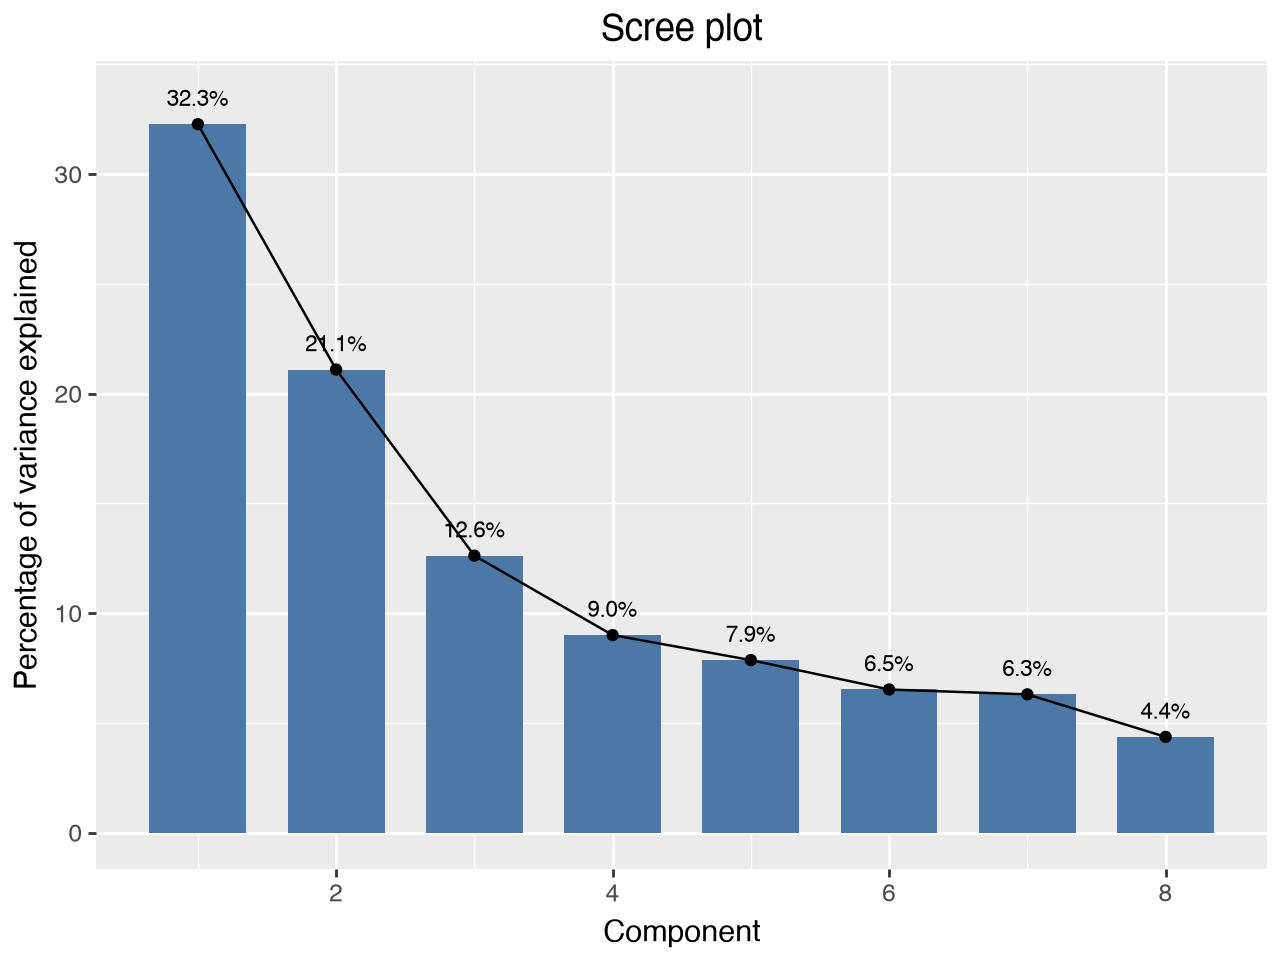

In [14]:
scree_ind = pd.DataFrame({
    "component": range(1, 9),
    "percent": prop_ind * 100
})

scree_ind["label"] = scree_ind["percent"].map(lambda p: f"{p:.1f}%")

(
    ggplot(scree_ind, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.2, size=8)
    + labs(
        x="Component",
        y="Percentage of variance explained",
        title="Scree plot"
    )
)

PCA loadings 

In [15]:
loadings_ind = pd.DataFrame(
    pca_ind.components_.T,
    index=ind_cols,
    columns=[f"PC{i}" for i in range(1, 9)]
)

print(loadings_ind.round(3))

                 PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8
income_cont    0.191  0.514 -0.184 -0.339  0.725 -0.150 -0.051 -0.027
prestg10       0.234  0.545  0.061  0.184 -0.389 -0.397  0.548  0.029
educ           0.278  0.512 -0.034  0.221 -0.278  0.496 -0.535 -0.019
age           -0.006  0.099  0.975 -0.129  0.109 -0.006 -0.084 -0.066
binary_lvmus   0.505 -0.197  0.050 -0.263 -0.061  0.058  0.020  0.791
binary_artxbt  0.467 -0.193  0.040  0.136  0.223  0.544  0.513 -0.339
binary_movie   0.448 -0.193 -0.064 -0.516 -0.331 -0.279 -0.230 -0.501
binary_creat   0.396 -0.232  0.052  0.657  0.266 -0.443 -0.295 -0.035


PC1 mainly represents cultural participation, as the four cultural-participation variables have the strongest positive loadings. PC2 mainly represents socioeconomic status, with strong positive loadings for income, occupational prestige, and education. PC3 is mainly an age-related component, as age has a very high loading on PC3.

PC1 and PC2 by happiness

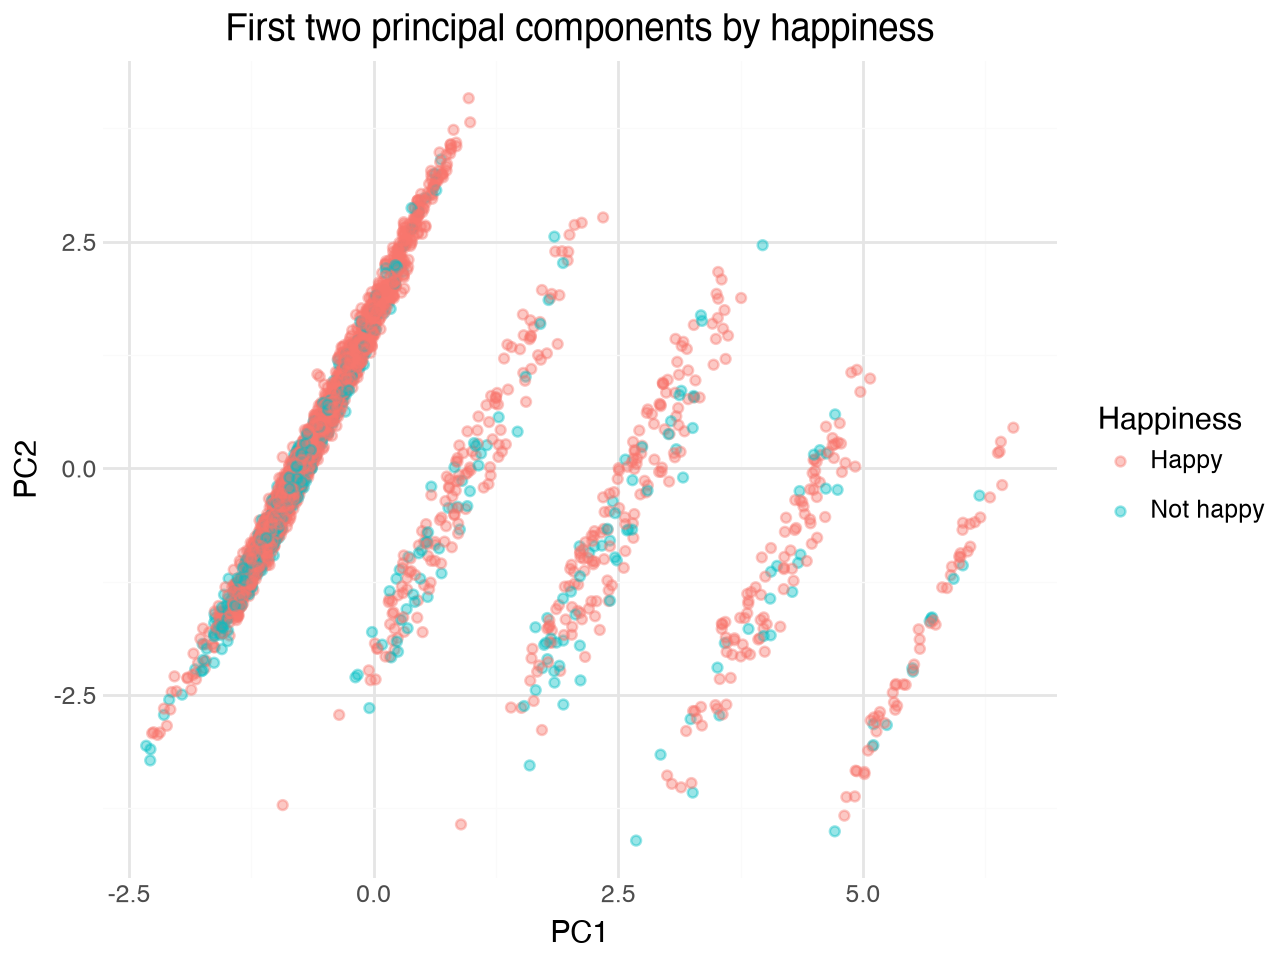

In [21]:
scores_ind = pca_ind.transform(X_ind)

ind_plot = ind_work.copy()
ind_plot["PC1"] = scores_ind[:, 0]
ind_plot["PC2"] = scores_ind[:, 1]
ind_plot["PC3"] = scores_ind[:, 2]

ind_plot["Happiness"] = np.where(
    ind_plot["happy_bin"] == 1,
    "Happy",
    "Not happy"
)

(
    ggplot(ind_plot, aes("PC1", "PC2", color="Happiness"))
    + geom_point(alpha=0.4, size=1.5)
    + theme_minimal()
    + labs(
        x="PC1",
        y="PC2",
        title="First two principal components by happiness"
    )
)

There is substantial overlap between happy and not-happy respondents, suggesting that the first two components do not visually separate the two groups clearly.

Logistic regression predicting happiness

In [19]:
ind_plot["PC3"] = scores_ind[:, 2]

In [22]:
happy_logit = smf.logit(
    "happy_bin ~ PC1 + PC2 + PC3",
    data=ind_plot
).fit()

print(happy_logit.summary())

Optimization terminated successfully.
         Current function value: 0.522364
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              happy_bin   No. Observations:                 2842
Model:                          Logit   Df Residuals:                     2838
Method:                           MLE   Df Model:                            3
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                 0.03086
Time:                        18:26:36   Log-Likelihood:                -1484.6
converged:                       True   LL-Null:                       -1531.8
Covariance Type:            nonrobust   LLR p-value:                 2.323e-20
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.2653      0.047     27.036      0.000       1.174       1.357
PC1            0.1053      0.

Converting logit coefficients to odds ratios

In [23]:
np.exp(happy_logit.params)

Intercept    3.544036
PC1          1.111042
PC2          1.378241
PC3          0.911836
dtype: float64

Interpretation of coefficient: PC1 and PC2 are positively associated with happiness, while PC3 is negatively associated with happiness. A one-unit increase in PC1 is associated with approximately 11% higher odds of being happy, while a one-unit increase in PC2 is associated with approximately 38% higher odds. In contrast, a one-unit increase in PC3 is associated with approximately 9% lower odds of being happy. All three coefficients are statistically significant at the 5% level.